In [1]:
%load_ext autoreload
%autoreload 2

# NF binned background template: validation of `src/nf_binned_template.py`

Component 01, DC4 511 keV binning. Does integrating the NF density over each bin give a correct template?

## 1. Setup

### 1.1 Imports

`set_global_style()` and `%matplotlib inline` go after the cosipy import.

In [2]:
import sys
from pathlib import Path
import h5py
import numpy as np
import torch                                   # raw NF density calls (Section 6.2)
import healpy as hp                            # sky maps
import astropy.units as u
from astropy.io import fits
from histpy import Histogram                   # notebook 08 reference histograms
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))     # project root, so `src` is importable
from src.nf_binned_template import NFBinnedTemplate   # imports cosipy

from src.plot_style import COLORS, set_global_style
set_global_style()                             # after cosipy

%matplotlib inline




WARNING FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.



### 1.2 Configuration

Paths, DC4 binning, time window, test settings (`QUAD`) and final settings (`FINAL`, from Sections 5–7).

In [3]:
# NF model (component 01) and orientation file
MODEL_PATH = Path("../model/nfbackground_part-01_v3-00.fits")
ORI_PATH = Path("../data/DC4_orientation.ori")

# Expected DC4 511 keV imaging binning (dataio_511.yaml), to check the reference histograms
EM_EDGES_KEV = [509.0, 513.0]          # 1 energy bin
PHI_EDGES_DEG = np.arange(0, 181, 3)   # 60 bins of 3 deg
NSIDE, SCHEME = 16, "ring"             # PsiChi: 3072 pixels

# Time window of the analysis [unix s]
TMIN, TMAX = 1835487300.036206, 1843467254.887687

# Reference histograms from notebook 08 (Em, Phi, PsiChi)
REF_PATHS = {
    "sim_local":    Path("../data/background_components/CosmicPhotons_511keV_DC4binning_local.hdf5"),
    "sim_galactic": Path("../data/background_components/CosmicPhotons_511keV_DC4binning_galactic.hdf5"),
    "nf_local":     Path("../data/NF_background/part-01_full_caffeinated_511keV_DC4binning_local.hdf5"),
    "nf_galactic":  Path("../data/NF_background/part-01_full_caffeinated_511keV_DC4binning_galactic.hdf5"),
}

# Simulated events of component 01 (unbinned, 10.9 GB), as in notebook 08
SIM_PATH = Path("../data/background_components/CosmicPhotons_3months_unbinned_data_filtered_with_SAAcut.fits")
NF_SAMPLES_PATH = Path("../data/NF_background/part-01_full_caffeinated.hdf5")
# Cheap integration settings for the tests: 2 Em points on each side of 511 keV, 1 Phi point per bin
# (the sky points, subpixel_level k, are given in each call)
QUAD = dict(n_em_per_bin=2, n_phi_per_bin=1, em_breaks_kev=[511.0])

# Final integration settings (from the convergence checks in Sections 5-7):
# Em 4 points per half, Phi 4 points per bin + bin 15-18 deg split at the edge (~16 deg)
FINAL = dict(n_em_per_bin=4, n_phi_per_bin=4,
             em_breaks_kev=[511.0], phi_breaks_deg=[15.5, 16.0, 16.5, 17.0])

## 2. Model normalization

`template` has the χ = 0 fix off (`seam_delta_deg=0`), to show the problem in Sections 7–8.

In [4]:
# [script] Create the template object from src/nf_binned_template.py: it only loads the NF model.
# seam_delta_deg=0 and polar_cap_deg=0 turn the chi = 0 and polar corrections off, so that Sections 5-8 show
# the problems as found (fixes: Sections 9 and 10)
template = NFBinnedTemplate(MODEL_PATH, seam_delta_deg=0, polar_cap_deg=0)

# [script] Numbers the template read from the model file: they set the rate R = counts / livetime
print(f"model version : {template.model_version}")
print(f"model_counts  : {template.model_counts:,.0f}")
print(f"model_livetime: {template.model_livetime:,.1f} s")

model version : 3.00
model_counts  : 97,554,902
model_livetime: 6,579,555.0 s


## 3. Binning

The template uses the axes of the notebook 08 histograms (`AXES`).

In [5]:
# Open the four notebook 08 histograms (simulation and NF samples, local and Galactic)
refs = {name: Histogram.open(path) for name, path in REF_PATHS.items()}

# For each one: Em and Phi edges as in dataio_511.yaml, and the same HEALPix grid for PsiChi?
for name, h in refs.items():
    ax = h.axes["PsiChi"]
    print(f"{name:13s} Em {np.allclose(h.axes['Em'].edges.to_value(u.keV), EM_EDGES_KEV)} | "
          f"Phi {np.allclose(h.axes['Phi'].edges.to_value(u.deg), PHI_EDGES_DEG)} | "
          f"nside {ax.nside}, {ax.scheme} | total {float(h.contents.sum()):,.0f}")

# Binning given to the script from now on: Em, Phi, PsiChi axes of the NF samples histogram
AXES = refs["nf_local"].axes

sim_local     Em True | Phi True | nside 16, RING | total 162,652
sim_galactic  Em True | Phi True | nside 16, RING | total 162,652
nf_local      Em True | Phi True | nside 16, RING | total 161,582
nf_galactic   Em True | Phi True | nside 16, RING | total 161,584


## 4. Test pixels

14 pixels: poles, brightest, equator, mid-latitudes. ~50 NF samples each (±14%).

In [6]:
# NF samples per local sky pixel: sum the notebook 08 histogram over Em and Phi -> 3072 numbers
nf_sky = np.asarray(refs["nf_local"].project("PsiChi").to_dense().contents)

# Pick the test pixels (RING numbering, like our PsiChi axis)
polar = np.array([0, 1, 2, 3, 3068, 3069, 3070, 3071])                       # first and last ring: the poles
brightest = np.argsort(nf_sky)[::-1][:3]                                      # 3 pixels with most samples
others = hp.ang2pix(NSIDE, np.deg2rad([90.0, 45.0, 135.0]), np.zeros(3))    # equator, mid-lat N and S
PIXELS = np.unique(np.concatenate([polar, brightest, others]))
n_obs = nf_sky[PIXELS]                                                        # NF samples in the test pixels (reference)

# Where each pixel is (colatitude 0 = spacecraft zenith) and how many samples it holds
colat_deg = np.rad2deg(hp.pix2ang(NSIDE, PIXELS)[0])
for p, c in zip(PIXELS, colat_deg):
    print(f"pixel {p:4d}  colatitude {c:6.1f} deg  NF samples {nf_sky[p]:6.0f}")

# [script] How many density evaluations the integral of these pixels needs with the final settings (cost before running)
print(f"cost with FINAL, k = 2: {template.n_evaluations(AXES, PIXELS, subpixel_level=2, **FINAL):,} evaluations")

pixel    0  colatitude    2.9 deg  NF samples     63
pixel    1  colatitude    2.9 deg  NF samples     64
pixel    2  colatitude    2.9 deg  NF samples     70
pixel    3  colatitude    2.9 deg  NF samples     54
pixel  420  colatitude   45.0 deg  NF samples     56
pixel 1440  colatitude   87.6 deg  NF samples     58
pixel 1469  colatitude   87.6 deg  NF samples     99
pixel 1510  colatitude   90.0 deg  NF samples    101
pixel 1562  colatitude   90.0 deg  NF samples     98
pixel 2592  colatitude  135.0 deg  NF samples     23
pixel 3068  colatitude  177.1 deg  NF samples     44
pixel 3069  colatitude  177.1 deg  NF samples     32
pixel 3070  colatitude  177.1 deg  NF samples     41
pixel 3071  colatitude  177.1 deg  NF samples     32
cost with FINAL, k = 2: 458,752 evaluations


## 5. Em convergence

More Em points must change the counts less and less (normal pixels, k = 1).

In [7]:
# Normal pixels only: no poles, no pixel 1440
normal = PIXELS[~np.isin(PIXELS, polar) & (PIXELS != 1440)]

# [script] Same pixels at k = 1, Phi fixed (1 point per bin), more Em points on each side of 511 keV
N_em = {}
for n_em in (2, 4, 8):
    template.compute(AXES, normal, subpixel_level=1, n_em_per_bin=n_em, n_phi_per_bin=1,
                     em_breaks_kev=[511.0], verbose=False)
    N_em[n_em] = template.expected_counts()[:, :, normal].sum(axis=(0, 1))   # counts per pixel

print("pixel  " + "  ".join(f"nEm={n:<5d}" for n in N_em))
for i, p in enumerate(normal):
    print(f"{p:5d}  " + "  ".join(f"{N_em[n][i]:9.2f}" for n in N_em))


pixel  nEm=2      nEm=4      nEm=8    
  420      45.70      45.61      45.55
 1469      79.84      79.69      79.59
 1510      80.55      80.39      80.30
 1562      85.01      84.85      84.74
 2592      29.70      29.65      29.61


## 6. Phi convergence

### 6.1 Points per Phi bin

In [8]:
# [script] Same pixels at k = 1, Em fixed (4 points on each side of 511 keV), more Phi points per bin
P_phi = {}
for n_phi in (1, 2, 4):
    template.compute(AXES, normal, subpixel_level=1, n_em_per_bin=4, n_phi_per_bin=n_phi,
                     em_breaks_kev=[511.0], verbose=False)
    P_phi[n_phi] = template.expected_counts()[0][:, normal].sum(axis=1)   # counts per Phi bin (60 values)

# Compare with the finest (4 points): total, and the largest change in a single Phi bin
ok = P_phi[4] > 0
for n_phi in (1, 2):
    rel = P_phi[n_phi][ok] / P_phi[4][ok] - 1
    print(f"nPhi={n_phi} vs 4: total {P_phi[n_phi].sum() / P_phi[4].sum() - 1:+.2%}, "
          f"largest change in one Phi bin {np.max(np.abs(rel)):.2%}")


nPhi=1 vs 4: total -0.14%, largest change in one Phi bin 99.79%
nPhi=2 vs 4: total +0.10%, largest change in one Phi bin 33.81%



WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True



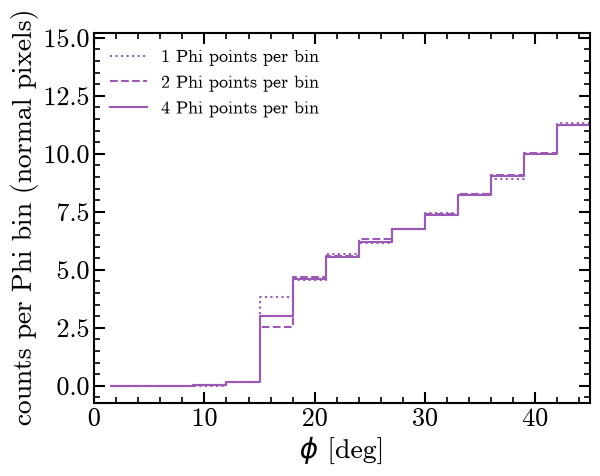

In [9]:
# Counts per Phi bin (normal pixels) for 1, 2 and 4 Phi points per bin, zoomed on 0-45 deg
phi_centres = 0.5 * (PHI_EDGES_DEG[:-1] + PHI_EDGES_DEG[1:])
for n_phi, ls in zip((1, 2, 4), (":", "--", "-")):
    plt.step(phi_centres, P_phi[n_phi], where="mid", ls=ls, color=COLORS["nf"], label=f"{n_phi} Phi points per bin")
plt.xlim(0, 45)
plt.xlabel(r"$\phi$ [deg]"); plt.ylabel("counts per Phi bin (normal pixels)"); plt.legend(); plt.show()


### 6.2 The edge at ~16°

In [10]:
# Cuts stored in the model: samples outside them are discarded by the flow
print("phi cuts [deg]:", np.rad2deg(template._density_model._phi_cuts), "| Em cuts [keV]:", template._density_model._menergy_cuts)


phi cuts [deg]: [  0. 180.] | Em cuts [keV]: [100, 10000]



WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True



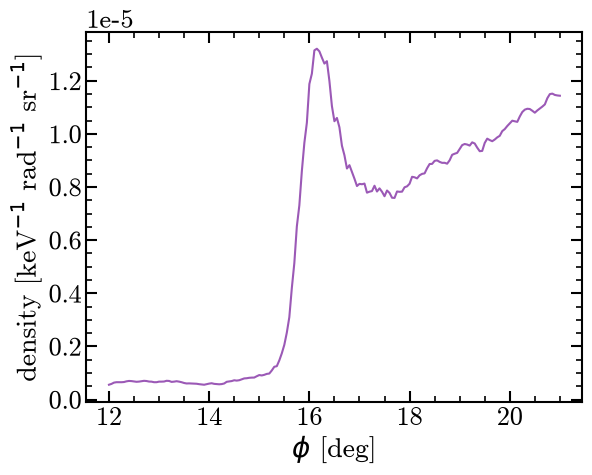

In [11]:
# NF density along phi (0.05 deg steps) at one sky point (centre of pixel 1510) and Em = 511 keV
phi_fine = np.linspace(12, 21, 181)                         # deg, 0.05 deg steps
colat_c, chi_c = hp.pix2ang(NSIDE, 1510)                    # centre of pixel 1510 [rad]
const = lambda x: torch.full((len(phi_fine),), x, dtype=torch.float64)

# [script] raw NF density at (Em = 511 keV, phi, chi, psi), the same call _density_on_grid makes
dens = template._density_model.evaluate_density(torch.zeros(len(phi_fine)), const(511.0),
                                                torch.from_numpy(np.deg2rad(phi_fine)), const(chi_c), const(colat_c))
plt.plot(phi_fine, dens.numpy(), color=COLORS["nf"])
plt.xlabel(r"$\phi$ [deg]"); plt.ylabel(r"density [keV$^{-1}$ rad$^{-1}$ sr$^{-1}$]"); plt.show()

In [12]:
# Read only Energies and Phi in chunks (memory map), keep the 509-513 keV events
phi_sim = []
with fits.open(SIM_PATH, memmap=True) as hdul:
    ev = hdul[1].data
    for a in range(0, len(ev), 1_000_000):
        e = ev["Energies"][a:a + 1_000_000]
        keep = (e >= 509.0) & (e < 513.0)
        phi_sim.append(np.rad2deg(np.asarray(ev["Phi"][a:a + 1_000_000][keep], dtype=np.float64)))
phi_sim = np.concatenate(phi_sim)
print(f"{len(phi_sim):,} simulated events in 509-513 keV")      # expect 162,652

# Fine histogram of phi around the edge (0.2 deg bins); plotted in the next cell
edges = np.arange(10, 25.01, 0.2)
n, _ = np.histogram(phi_sim, bins=edges)

162,652 simulated events in 509-513 keV


161,582 NF samples in 509-513 keV



WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True



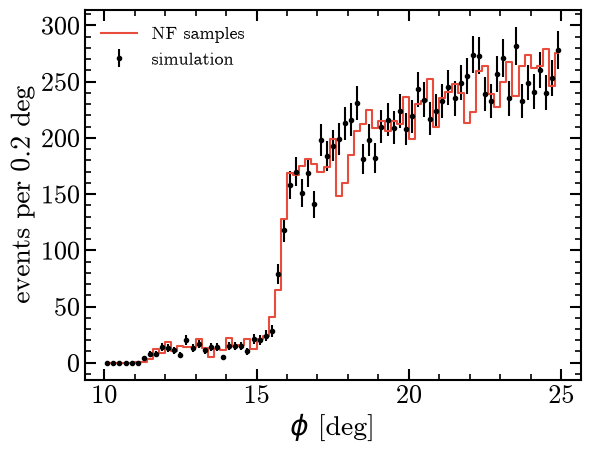

In [13]:
# Read Energies and Phi of the NF samples in chunks, keep 509-513 keV (as for the simulation)
phi_nf = []
with h5py.File(NF_SAMPLES_PATH, "r") as f:
    for a in range(0, f["Energies"].shape[0], 1_000_000):
        e = f["Energies"][a:a + 1_000_000]
        keep = (e >= 509.0) & (e < 513.0)
        phi_nf.append(np.rad2deg(f["Phi"][a:a + 1_000_000][keep]))
phi_nf = np.concatenate(phi_nf)
print(f"{len(phi_nf):,} NF samples in 509-513 keV")      # expect 161,582

# Same fine histogram, overlaid on the simulation
n_nf, _ = np.histogram(phi_nf, bins=edges)
centres = 0.5 * (edges[:-1] + edges[1:])
plt.errorbar(centres, n, yerr=np.sqrt(n), fmt=".", color=COLORS["sim"], label="simulation")
plt.step(centres, n_nf, where="mid", color=COLORS["nf_samples"], label="NF samples")
plt.xlabel(r"$\phi$ [deg]"); plt.ylabel("events per 0.2 deg"); plt.legend(); plt.show()


### 6.3 Fix: split bin 15–18°

Split at 15.5, 16, 16.5, 17°, with its own points per piece.

In [14]:
# [script] Same normal pixels at k = 1, Em 4 points per half; bin 15-18 deg split into 5 pieces
P_split = {}
for n_phi in (2, 4):
    template.compute(AXES, normal, subpixel_level=1, n_em_per_bin=4, n_phi_per_bin=n_phi,
                     em_breaks_kev=[511.0], phi_breaks_deg=[15.5, 16.0, 16.5, 17.0], verbose=False)
    P_split[n_phi] = template.expected_counts()[0][:, normal].sum(axis=1)   # counts per Phi bin

b = 5   # index of bin 15-18 deg
print(f"bin 15-18 deg, no split : 1 pt {P_phi[1][b]:.3f} | 2 pts {P_phi[2][b]:.3f} | 4 pts {P_phi[4][b]:.3f}")
print(f"bin 15-18 deg, split    : 2 pts {P_split[2][b]:.3f} | 4 pts {P_split[4][b]:.3f}")


bin 15-18 deg, no split : 1 pt 3.812 | 2 pts 2.512 | 4 pts 3.022
bin 15-18 deg, split    : 2 pts 2.922 | 4 pts 2.924


In [15]:
# [script] Same settings with 8 Phi points per bin (and the split), then the bins that change most from 4 to 8
template.compute(AXES, normal, subpixel_level=1, n_em_per_bin=4, n_phi_per_bin=8,
                 em_breaks_kev=[511.0], phi_breaks_deg=[15.5, 16.0, 16.5, 17.0], verbose=False)
P_split[8] = template.expected_counts()[0][:, normal].sum(axis=1)

ok = P_split[4] > 0.1                                   # non-empty Phi bins

rel48 = np.where(ok, P_split[4] / np.where(ok, P_split[8], 1) - 1, 0)
for b in np.argsort(np.abs(rel48))[::-1][:3]:
    print(f"Phi {PHI_EDGES_DEG[b]:3.0f}-{PHI_EDGES_DEG[b + 1]:3.0f} deg:  4 pts {P_split[4][b]:7.3f}  8 pts {P_split[8][b]:7.3f}  change {rel48[b]:+.2%}")


Phi  12- 15 deg:  4 pts   0.152  8 pts   0.154  change -1.61%
Phi  18- 21 deg:  4 pts   4.588  8 pts   4.620  change -0.71%
Phi 174-177 deg:  4 pts   0.239  8 pts   0.240  change -0.68%



WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True



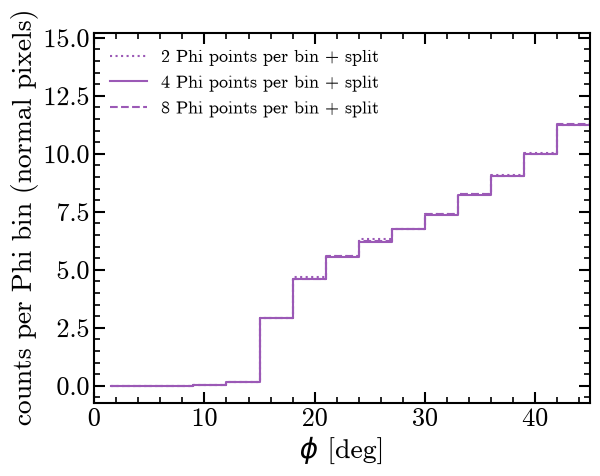

In [16]:
# Counts per Phi bin (normal pixels) with the split at 15.5-17 deg, for 2, 4 and 8 Phi points per bin (FINAL = 4)
for n_phi, ls in zip((2, 4, 8), (":", "-", "--")):
    plt.step(phi_centres, P_split[n_phi], where="mid", ls=ls, color=COLORS["nf"], label=f"{n_phi} Phi points per bin + split")
plt.xlim(0, 45)
plt.xlabel(r"$\phi$ [deg]"); plt.ylabel("counts per Phi bin (normal pixels)"); plt.legend(); plt.show()


WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True



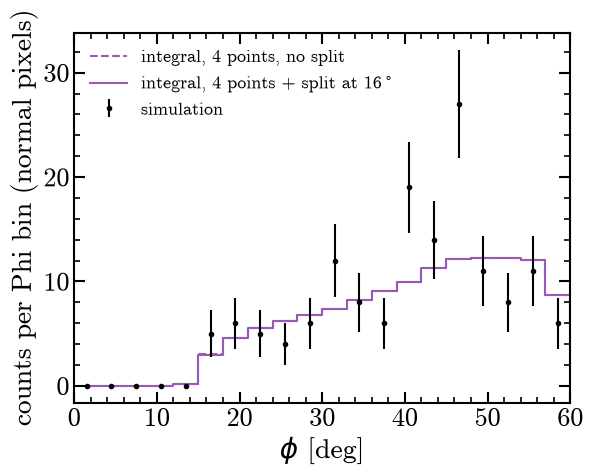

In [17]:
# Counts per Phi bin in the normal pixels: integral before/after the split, and the simulation
sim_phi = np.asarray(refs["sim_local"].project("Phi", "PsiChi").to_dense().contents)[:, normal].sum(axis=1)
phi_centres = 0.5 * (PHI_EDGES_DEG[:-1] + PHI_EDGES_DEG[1:])

plt.step(phi_centres, P_phi[4], where="mid", ls="--", color=COLORS["nf"], label="integral, 4 points, no split")
plt.step(phi_centres, P_split[4], where="mid", color=COLORS["nf"], label=r"integral, 4 points + split at 16$^\circ$")
plt.errorbar(phi_centres, sim_phi, yerr=np.sqrt(sim_phi), fmt=".", color=COLORS["sim"], label="simulation")
plt.xlim(0, 60)
plt.xlabel(r"$\phi$ [deg]"); plt.ylabel("counts per Phi bin (normal pixels)"); plt.legend(); plt.show()


WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True



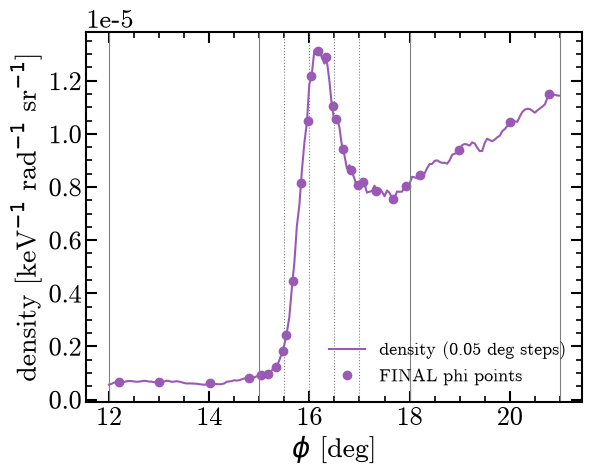

In [18]:
# Same density curve (centre of pixel 1510, Em = 511 keV), with the phi points used by the FINAL integral marked on it
template.compute(AXES, [1510], subpixel_level=2, verbose=False, **FINAL)    # [script] sets the FINAL phi points
phi_nodes = np.rad2deg(template.phi_nodes_rad)                              # [script] all FINAL phi points [deg]
phi_nodes = phi_nodes[(phi_nodes >= 12) & (phi_nodes <= 21)]                 # only those in the plotted range

# Raw NF density at the fine phi steps and at the FINAL phi points (same call as before)
def density_at(phi_deg):
    const = lambda x: torch.full((len(phi_deg),), x, dtype=torch.float64)
    return template._density_model.evaluate_density(torch.zeros(len(phi_deg)), const(511.0),
                                                    torch.from_numpy(np.deg2rad(phi_deg)), const(chi_c), const(colat_c)).numpy()

plt.plot(phi_fine, density_at(phi_fine), color=COLORS["nf"], label="density (0.05 deg steps)")
plt.plot(phi_nodes, density_at(phi_nodes), "o", color=COLORS["nf"], label="FINAL phi points")
for e in PHI_EDGES_DEG[(PHI_EDGES_DEG >= 12) & (PHI_EDGES_DEG <= 21)]:
    plt.axvline(e, color=COLORS["ref"], ls="-", lw=0.8)                     # 3 deg bin edges
for b in FINAL["phi_breaks_deg"]:
    plt.axvline(b, color=COLORS["ref"], ls=":", lw=0.8)                     # split points inside bin 15-18 deg
plt.xlabel(r"$\phi$ [deg]"); plt.ylabel(r"density [keV$^{-1}$ rad$^{-1}$ sr$^{-1}$]"); plt.legend(); plt.show()


***
## 7. Sky convergence

k = sub-pixel level (4^k sky points per pixel). `QUAD` for Em and Phi, so only the sky changes.

### 7.1 All test pixels, k = 0–3

In [19]:
# Same pixels, more sky points per pixel: 4**k points, k = 0, 1, 2, 3 (Em and Phi points unchanged)
N_k = {}
for k in range(4):
    template.compute(AXES, PIXELS, subpixel_level=k, verbose=False, **QUAD)    # [script] the integral, at level k
    N_k[k] = template.expected_counts()[:, :, PIXELS].sum(axis=(0, 1))     # [script] counts N = model_counts * P

# One row per pixel: how the counts change with k, next to the NF samples
print("pixel  " + "  ".join(f"k={k:<5d}" for k in N_k) + "  NF samples")
for i, p in enumerate(PIXELS):
    print(f"{p:5d}  " + "  ".join(f"{N_k[k][i]:7.1f}" for k in N_k) + f"  {n_obs[i]:6.0f}")

pixel  k=0      k=1      k=2      k=3      NF samples
    0    107.6     56.9     49.8     55.8      63
    1    110.3     57.8     50.3     56.9      64
    2    110.8     57.9     49.8     56.3      70
    3    104.2     57.6     49.4     56.0      54
  420     45.5     45.7     45.6     45.9      56
 1440      7.2     26.9     37.5     42.9      58
 1469     79.8     79.8     80.0     80.0      99
 1510     84.5     80.5     79.5     79.4     101
 1562     89.3     85.0     83.7     83.6      98
 2592     29.9     29.7     30.0     30.3      23
 3068     52.2     29.7     27.6     31.8      44
 3069     51.5     29.5     27.4     31.6      32
 3070     51.3     30.3     27.5     31.6      41
 3071     54.2     29.8     28.0     32.4      32


### 7.2 Polar pixels and pixel 1440, k = 4–5

In [20]:
# [script] The 8 polar pixels and pixel 1440 at k = 4 and 5 (256 and 1024 sky points per pixel)
slow = np.append(polar, 1440)
for k in (4, 5):
    template.compute(AXES, slow, subpixel_level=k, verbose=False, **QUAD)
    N_k[k] = template.expected_counts()[:, :, PIXELS].sum(axis=(0, 1))   # counts per test pixel

# Rows of these pixels only (the others were not recomputed at k = 4, 5)
print("pixel  " + "  ".join(f"k={k:<5d}" for k in N_k) + "  NF samples")
for i in np.flatnonzero(np.isin(PIXELS, slow)):
    print(f"{PIXELS[i]:5d}  " + "  ".join(f"{N_k[k][i]:7.1f}" for k in N_k) + f"  {n_obs[i]:6.0f}")

pixel  k=0      k=1      k=2      k=3      k=4      k=5      NF samples
    0    107.6     56.9     49.8     55.8     61.1     64.3      63
    1    110.3     57.8     50.3     56.9     61.1     61.7      64
    2    110.8     57.9     49.8     56.3     60.4     61.3      70
    3    104.2     57.6     49.4     56.0     61.4     64.6      54
 1440      7.2     26.9     37.5     42.9     45.5     46.7      58
 3068     52.2     29.7     27.6     31.8     35.5     37.7      44
 3069     51.5     29.5     27.4     31.6     33.6     33.9      32
 3070     51.3     30.3     27.5     31.6     33.7     34.1      41
 3071     54.2     29.8     28.0     32.4     35.9     38.1      32


## 8. Why: the density near χ = 0

Density along lines on the sky, in counts per pixel area.
The pole and the comparison with the simulation are in notebook 08b.

### 8.1 Tool and check

In [21]:
# Em/Phi points at QUAD: the weights below are those of the last compute
template.compute(AXES, [1440], subpixel_level=0, verbose=False, **QUAD)

# Sky density of the NF, integrated over the Em bin and all Phi, converted to counts per pixel area
# (same units as the table: model_counts x density [1/sr] x pixel area [sr])
w_em = template._em_matrix.sum(axis=0)       # [script] weight of each Em point 
w_phi = template._phi_matrix.sum(axis=0)     # [script] weight of each Phi point
pix_area = hp.nside2pixarea(NSIDE)           # [sr]

def counts_per_pixel_area(colat_deg, chi_deg):
    # [script] NF density at (Em points) x (Phi points) x (sky points), then the weighted sum over Em and Phi
    p = template._density_on_grid(np.deg2rad(colat_deg), np.deg2rad(np.mod(chi_deg, 360)))
    return template.model_counts * np.einsum("e,p,eps->s", w_em, w_phi, p) * pix_area

In [22]:
# Check of the tool at the centre of pixel 1440: must give its k = 0 value in the table of Section 7.1 (7.2 counts)
colat_1440, chi_1440 = np.rad2deg(hp.pix2ang(NSIDE, 1440))   # centre of pixel 1440 [deg]
print(counts_per_pixel_area(np.array([colat_1440]), np.array([chi_1440])))

[7.22801233]


### 8.2 Across χ = 0 and toward the pole


WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True



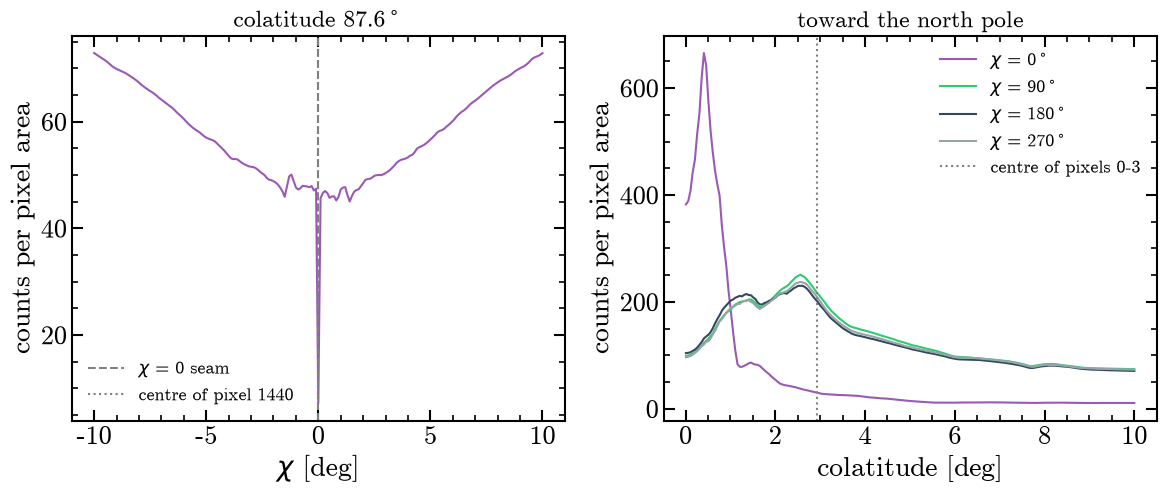

In [23]:
# Density along two lines: across the chi = 0 seam (left) and toward the north pole (right)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Across the chi = 0 seam, at the colatitude of pixel 1440
chi = np.linspace(-10, 10, 201)
ax1.plot(chi, counts_per_pixel_area(np.full_like(chi, colat_1440), chi), color=COLORS["nf"])
ax1.axvline(0, color=COLORS["ref"], ls="--", label=r"$\chi$ = 0 seam")
ax1.axvline(chi_1440, color=COLORS["ref"], ls=":", label="centre of pixel 1440")
ax1.set(xlabel=r"$\chi$ [deg]", ylabel="counts per pixel area", title=rf"colatitude {colat_1440:.1f}$^\circ$")
ax1.legend()

# 2. Toward the pole, at four longitudes
colat = np.linspace(0.01, 10, 201)
for chi0 in (0, 90, 180, 270):
    ax2.plot(colat, counts_per_pixel_area(colat, np.full_like(colat, chi0)), label=rf"$\chi$ = {chi0}$^\circ$")
ax2.axvline(np.rad2deg(hp.pix2ang(NSIDE, 0)[0]), color=COLORS["ref"], ls=":", label="centre of pixels 0-3")
ax2.set(xlabel="colatitude [deg]", ylabel="counts per pixel area", title="toward the north pole")
ax2.legend()
plt.show()

### 8.3 Width of the strip


WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True



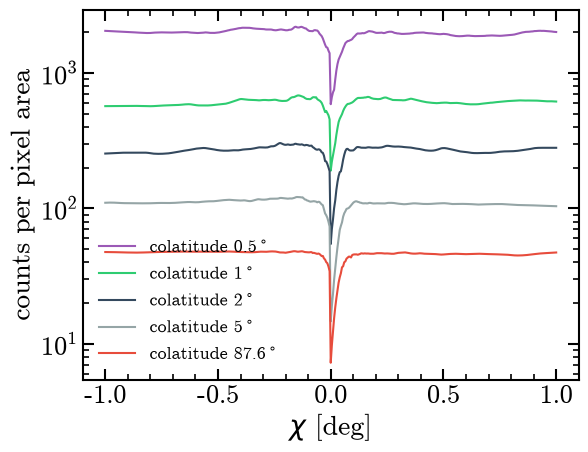

In [24]:
# Density across chi = 0 at several colatitudes: how wide is the anomaly in chi?
chi = np.linspace(-1, 1, 401)
for colat in (0.5, 1, 2, 5, 87.6):
    plt.plot(chi, counts_per_pixel_area(np.full_like(chi, colat), np.mod(chi, 360)), label=rf"colatitude {colat}$^\circ$")
plt.yscale("log"); plt.xlabel(r"$\chi$ [deg]"); plt.ylabel("counts per pixel area"); plt.legend(); plt.show()

## 9. The χ = 0 fix

In the script: `seam_delta_deg` (default 0.2°) moves sky points with χ < δ to δ, and χ > 360° − δ to 360° − δ.
It applies to every pixel. `template_fix` has it on.

### 9.1 With and without the fix

Pixel 1440, polar pixels next to χ = 0, and polar controls, k = 0–5. "No fix" is taken from Section 7. ~8 min.

In [25]:
# [script] Second template, with the chi = 0 fix (default seam_delta_deg = 0.2 deg) and the polar refinement off
# (Section 10 tests it)
template_fix = NFBinnedTemplate(MODEL_PATH, polar_cap_deg=0)
print(f"seam_delta_deg: template {np.rad2deg(template.seam_delta_rad):.2f} | template_fix {np.rad2deg(template_fix.seam_delta_rad):.2f}")

# Pixel on chi = 0, polar pixels next to chi = 0, other polar pixels (control)
test_pix = np.array([1440, 0, 3, 3068, 3071, 1, 2, 3069, 3070])

# [script] Closest sky point to chi = 0 in each pixel at k = 5 [deg]: only points closer than delta are moved by the fix
_, lon5, _ = NFBinnedTemplate._healpix_subpixel_nodes(NSIDE, 5, test_pix, nest=(SCHEME == "nested"))
dist5 = np.rad2deg(np.minimum(lon5, 2 * np.pi - lon5)).min(axis=1)
print("closest sky point to chi = 0 at k = 5 [deg]:", dict(zip(test_pix.tolist(), dist5.round(3).tolist())))

# Counts per pixel for k = 0..5 (QUAD): without the fix from Section 7 (N_k), with the fix computed here
rows = np.searchsorted(PIXELS, test_pix)                       # position of each test pixel in PIXELS
N_seam = {"no fix": {k: N_k[k][rows] for k in range(6)}, "fix": {}}
for k in range(6):
    template_fix.compute(AXES, test_pix, subpixel_level=k, verbose=False, **QUAD)   # [script]
    N_seam["fix"][k] = template_fix.expected_counts()[:, :, test_pix].sum(axis=(0, 1))

print("pixel  fix?    " + "  ".join(f"k={k:<5d}" for k in range(6)) + "  NF samples")
for i, p in enumerate(test_pix):
    for name in N_seam:
        print(f"{p:5d}  {name:6s}  " + "  ".join(f"{N_seam[name][k][i]:7.1f}" for k in range(6)) + f"  {nf_sky[p]:6.0f}")

seam_delta_deg: template 0.00 | template_fix 0.20
closest sky point to chi = 0 at k = 5 [deg]: {1440: 0.0, 0: 1.406, 3: 1.406, 3068: 1.406, 3071: 1.406, 1: 91.406, 2: 91.406, 3069: 91.406, 3070: 91.406}
pixel  fix?    k=0      k=1      k=2      k=3      k=4      k=5      NF samples
 1440  no fix      7.2     26.9     37.5     42.9     45.5     46.7      58
 1440  fix        46.6     46.9     47.6     48.0     48.0     48.0      58
    0  no fix    107.6     56.9     49.8     55.8     61.1     64.3      63
    0  fix       107.6     56.9     49.8     55.8     61.1     64.3      63
    3  no fix    104.2     57.6     49.4     56.0     61.4     64.6      54
    3  fix       104.2     57.6     49.4     56.0     61.4     64.6      54
 3068  no fix     52.2     29.7     27.6     31.8     35.5     37.7      44
 3068  fix        52.2     29.7     27.6     31.8     35.5     37.7      44
 3071  no fix     54.2     29.8     28.0     32.4     35.9     38.1      32
 3071  fix        54.2     29.8  


WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True



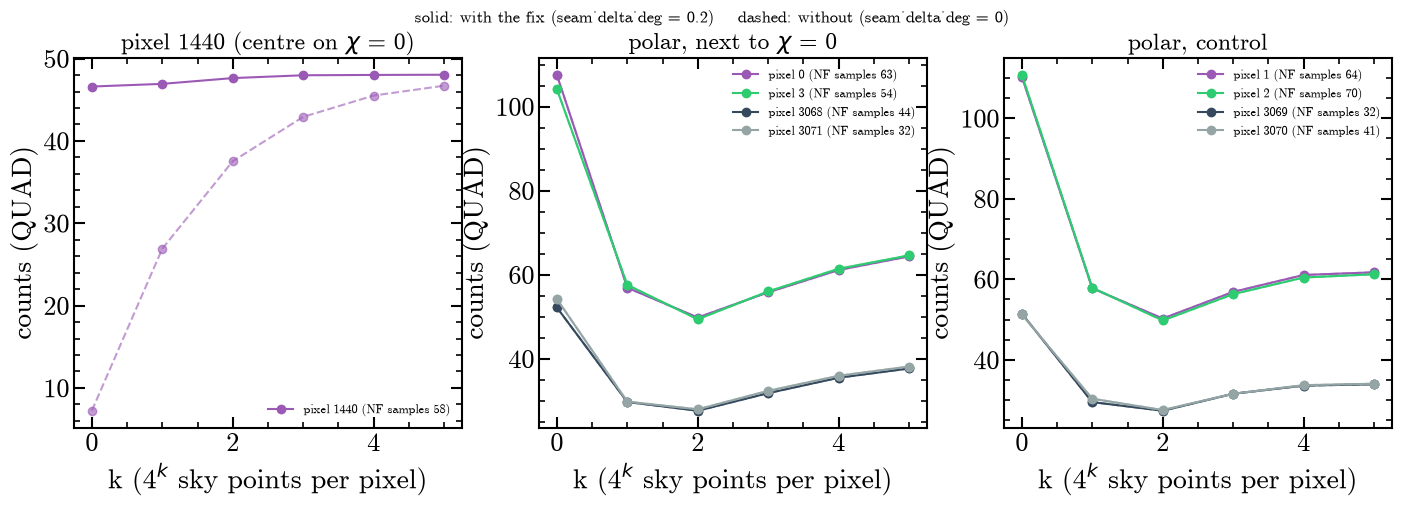

In [26]:
# Counts vs k, without (dashed) and with (solid) the fix, in three groups of pixels
groups = {r"pixel 1440 (centre on $\chi$ = 0)": [1440],
          r"polar, next to $\chi$ = 0": [0, 3, 3068, 3071],
          "polar, control": [1, 2, 3069, 3070]}
ks = np.arange(6)

fig, axs = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (title, pix) in zip(axs, groups.items()):
    for j, p in enumerate(pix):
        i = np.flatnonzero(test_pix == p)[0]                       # row of pixel p in N_seam
        ax.plot(ks, [N_seam["no fix"][k][i] for k in ks], "o--", color=f"C{j}", alpha=0.6)
        ax.plot(ks, [N_seam["fix"][k][i] for k in ks], "o-", color=f"C{j}", label=f"pixel {p} (NF samples {nf_sky[p]:.0f})")
    ax.set(title=title, xlabel=r"k (4$^k$ sky points per pixel)", ylabel="counts (QUAD)")
    ax.legend(fontsize=9)
fig.suptitle(r"solid: with the fix ($\delta$ = 0.2$^\circ$)    dashed: without ($\delta$ = 0)")
plt.show()

### 9.2 Dependence on δ

Pixel 1440 for δ = 0, 0.03, 0.1, 0.2, 0.3°. ~5 min.

In [27]:
# [script] Pixel 1440 at k = 0..5 (QUAD) for several seam_delta_deg; one template per delta (each loads the model)
N_delta = {}
for delta_deg in (0.0, 0.03, 0.1, 0.2, 0.3):
    t = NFBinnedTemplate(MODEL_PATH, seam_delta_deg=delta_deg)
    N_delta[delta_deg] = [t.compute(AXES, [1440], subpixel_level=k, verbose=False, **QUAD).sum() * t.model_counts
                          for k in range(6)]          # compute returns P of the pixel; x model_counts -> counts

print("seam_delta_deg  " + "  ".join(f"k={k:<5d}" for k in range(6)) + "  NF samples")
for delta_deg, row in N_delta.items():
    print(f"{delta_deg:14.2f}  " + "  ".join(f"{v:7.1f}" for v in row) + f"  {nf_sky[1440]:6.0f}")

seam_delta_deg  k=0      k=1      k=2      k=3      k=4      k=5      NF samples
          0.00      7.2     26.9     37.5     42.9     45.5     46.7      58
          0.03     24.8     36.0     42.1     45.2     46.7     47.3      58
          0.10     45.6     46.4     47.4     47.9     48.0     48.0      58
          0.20     46.6     46.9     47.6     48.0     48.0     48.0      58
          0.30     47.0     47.1     47.7     48.0     48.1     48.1      58


## 10. Polar pixels: refinement near the pole

Pixel 0 with `template_fix` and `QUAD`: uniform k = 6, 7 (reference) vs k = 5 with only the sub-pixels
near the pole split further; then pixel 3068 and pixel 0 with `FINAL`.
The chosen rule (1°, k$_\mathrm{pole}$ = 7) is in the script: `polar_cap_deg`, `polar_subpixel_level`,
`pole_colat_deg`, `pole_subpixel_level`.

In [29]:
# Em/Phi points at QUAD, and their weights (the integral of one pixel = sum over Em, Phi and sky points)
template_fix.compute(AXES, [0], subpixel_level=0, verbose=False, **QUAD)    # [script] sets the QUAD points
w_em_q = template_fix._em_matrix.sum(axis=0)                                 # [script] weight of each Em point
w_phi_q = template_fix._phi_matrix.sum(axis=0)                               # [script] weight of each Phi point

In [30]:
def polar_refined_nodes(pixel, k, k_pole, colat_max_deg):
    """4**k sub-pixels of one pixel; those with centre within colat_max_deg of a pole are split further to level k_pole.
    Returns colatitude, longitude [rad] and weight [sr] of every sky point."""
    children = hp.ring2nest(NSIDE, pixel) * 4**k + np.arange(4**k)          # NESTED children at NSIDE * 2**k
    colat_c, _ = hp.pix2ang(NSIDE * 2**k, children, nest=True)
    near = np.minimum(colat_c, np.pi - colat_c) < np.deg2rad(colat_max_deg)  # sub-pixels close to a pole
    m = 4**(k_pole - k)
    fine = (children[near][:, None] * m + np.arange(m)).ravel()            # their children at NSIDE * 2**k_pole
    colat_a, lon_a = hp.pix2ang(NSIDE * 2**k, children[~near], nest=True)
    colat_b, lon_b = hp.pix2ang(NSIDE * 2**k_pole, fine, nest=True)
    w = np.concatenate([np.full(len(colat_a), hp.nside2pixarea(NSIDE * 2**k)),
                        np.full(len(colat_b), hp.nside2pixarea(NSIDE * 2**k_pole))])
    return np.concatenate([colat_a, colat_b]), np.concatenate([lon_a, lon_b]), w

def counts_from_nodes(colat, lon, w_sky, chunk=10_000):
    """Counts of one pixel from its sky points: model_counts x sum(w_em x w_phi x density x w_sky)."""
    total = 0.0
    for a in range(0, len(colat), chunk):
        p = template_fix._density_on_grid(colat[a:a + chunk], lon[a:a + chunk])   # [script] (Em, Phi, sky), fix applied
        total += np.einsum("e,p,eps,s->", w_em_q, w_phi_q, p, w_sky[a:a + chunk])
    return template_fix.model_counts * total

In [31]:
# Checks: weights add up to the pixel area, and no refinement reproduces k = 5 of Section 9.1 (64.3)
colat, lon, w = polar_refined_nodes(0, 5, 5, 0.0)
print(f"area ratio {w.sum() / hp.nside2pixarea(NSIDE):.6f} | k = 5: {counts_from_nodes(colat, lon, w):.1f}")

area ratio 1.000000 | k = 5: 64.3


In [33]:
# [script] Pixel 0 at uniform k = 6 and 7 (QUAD): the slow reference
N_uniform = {}
for k in (6, 7):
    template_fix.compute(AXES, [0], subpixel_level=k, verbose=True, **QUAD)
    N_uniform[k] = template_fix.expected_counts()[:, :, 0].sum()
print({k: round(v, 1) for k, v in N_uniform.items()})


1 pixels, k = 6: 983,040 evaluations in 1 chunks of up to 2 pixels
  chunk 1/1: 1/1 pixels, 154 s, 6,376 evaluations/s
1 pixels, k = 7: 3,932,160 evaluations in 1 chunks of up to 1 pixels
  chunk 1/1: 1/1 pixels, 740 s, 5,311 evaluations/s
{6: np.float64(66.0), 7: np.float64(66.4)}


In [38]:
# k = 5 in the pixel; sub-pixels within colat_max of the pole refined to k_pole. Compared with uniform k = 7
refined = {}                                   # (colat_max, k_pole) -> (sky points, counts), used by the plot
print("colat_max  k_pole  sky points  counts  vs k = 7")
for colat_max in (1.0, 2.0):
    for k_pole in (6, 7, 8):
        colat, lon, w = polar_refined_nodes(0, 5, k_pole, colat_max)
        refined[colat_max, k_pole] = (len(w), counts_from_nodes(colat, lon, w))
        n, N = refined[colat_max, k_pole]
        print(f"{colat_max:6.1f} deg  {k_pole:6d}  {n:10,d}  {N:6.1f}  {N / N_uniform[7] - 1:+7.2%}")



colat_max  k_pole  sky points  counts  vs k = 7
   1.0 deg       6       1,189    65.9   -0.74%
   1.0 deg       7       1,849    66.3   -0.13%
   1.0 deg       8       4,489    66.4   +0.03%
   2.0 deg       6       1,717    65.9   -0.70%
   2.0 deg       7       4,489    66.4   -0.03%
   2.0 deg       8      15,577    66.5   +0.13%



WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True



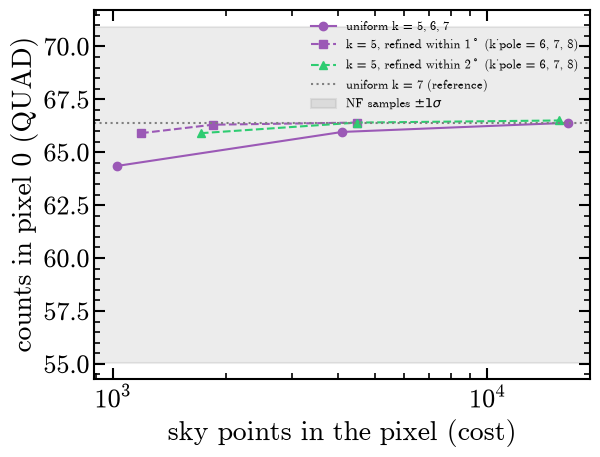

In [37]:
# Counts of pixel 0 vs cost (sky points): uniform k = 5, 6, 7 and the refinement near the pole; NF samples for reference
n_uni = {k: 4**k for k in (5, 6, 7)}
N_uni = {5: N_seam["fix"][5][np.flatnonzero(test_pix == 0)[0]], **N_uniform}
plt.plot([n_uni[k] for k in n_uni], [N_uni[k] for k in n_uni], "o-", color=COLORS["nf"], label="uniform k = 5, 6, 7")
for colat_max, marker in ((1.0, "s"), (2.0, "^")):
    pts = [refined[colat_max, kp] for kp in (6, 7, 8)]
    plt.plot([p[0] for p in pts], [p[1] for p in pts], marker + "--", label=rf"k = 5, refined within {colat_max:.0f}$^\circ$ (k$_\mathrm{{pole}}$ = 6, 7, 8)")
plt.axhline(N_uniform[7], color=COLORS["ref"], ls=":", label="uniform k = 7 (reference)")
plt.axhspan(nf_sky[0] - np.sqrt(nf_sky[0]), nf_sky[0] + np.sqrt(nf_sky[0]), color=COLORS["ref"], alpha=0.15, label=r"NF samples $\pm 1\sigma$")
plt.xscale("log"); plt.xlabel("sky points in the pixel (cost)"); plt.ylabel("counts in pixel 0 (QUAD)")
plt.legend(fontsize=9); plt.show()


In [ ]:
# Same check on pixel 3068 (south pole): uniform k = 5 (Section 9.1), refined (1 deg, k_pole = 7), uniform k = 7
pix = 3068
N_k5 = N_seam["fix"][5][np.flatnonzero(test_pix == pix)[0]]
colat, lon, w = polar_refined_nodes(pix, 5, 7, 1.0)          # also uses the QUAD nodes
N_ref = counts_from_nodes(colat, lon, w)
template_fix.compute(AXES, [pix], subpixel_level=7, verbose=True, **QUAD)   # slow, ~12 min


1 pixels, k = 7: 3,932,160 evaluations in 1 chunks of up to 1 pixels
  chunk 1/1: 1/1 pixels, 722 s, 5,445 evaluations/s
pixel 3068: k = 5 37.7 (-43.25%) | refined 38.7 (-41.78%, 1,849 points) | k = 7 66.4


In [42]:
N_k7 = template_fix.expected_counts()[:, :, pix].sum()
print(f"pixel {pix}: k = 5 {N_k5:.1f} ({N_k5 / N_k7 - 1:+.2%}) | refined {N_ref:.1f} ({N_ref / N_k7 - 1:+.2%}, {len(w):,} points) | k = 7 {N_k7:.1f}")


pixel 3068: k = 5 37.7 (-2.28%) | refined 38.7 (+0.25%, 1,849 points) | k = 7 38.6



WARNING UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True



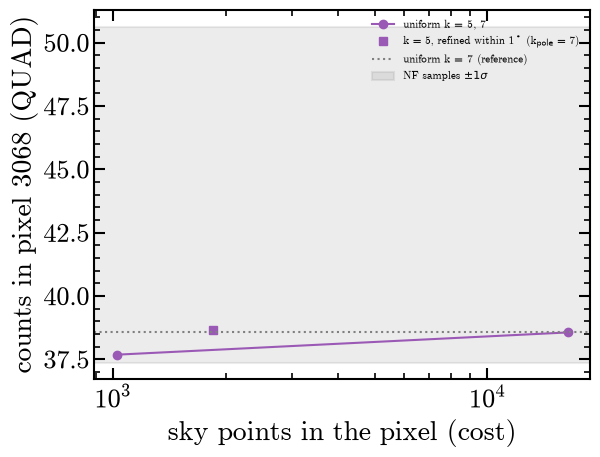

In [43]:
# Pixel 3068: counts vs cost for uniform k = 5, refined (1 deg, k_pole = 7) and uniform k = 7 (reference)
plt.plot([4**5, 4**7], [N_k5, N_k7], "o-", color=COLORS["nf"], label="uniform k = 5, 7")
plt.plot(len(w), N_ref, "s", label=r"k = 5, refined within 1$^\circ$ (k$_\mathrm{pole}$ = 7)")
plt.axhline(N_k7, color=COLORS["ref"], ls=":", label="uniform k = 7 (reference)")
plt.axhspan(nf_sky[pix] - np.sqrt(nf_sky[pix]), nf_sky[pix] + np.sqrt(nf_sky[pix]), color=COLORS["ref"], alpha=0.15, label=r"NF samples $\pm 1\sigma$")
plt.xscale("log")
plt.xlabel("sky points in the pixel (cost)")
plt.ylabel(f"counts in pixel {pix} (QUAD)")
plt.legend(fontsize=8)
plt.show()


In [45]:
# Pixel 0 with FINAL: uniform k = 7 (reference) vs refined (1 deg, k_pole = 7) vs uniform k = 5
template_fix.compute(AXES, [0], subpixel_level=7, verbose=True, **FINAL)   # slow, ~95 min; sets the FINAL Em/Phi nodes

N_final = {"k = 7": template_fix.expected_counts()[:, :, 0].sum()}
w_em_q, w_phi_q = template_fix._em_matrix.sum(axis=0), template_fix._phi_matrix.sum(axis=0)   # FINAL weights for counts_from_nodes

for name, (k_pole, colat_max) in {"refined": (7, 1.0), "k = 5": (5, 0.0)}.items():
    colat, lon, w = polar_refined_nodes(0, 5, k_pole, colat_max)
    N_final[name] = counts_from_nodes(colat, lon, w)

for name, N in N_final.items():
    print(f"{name:8s} {N:6.1f}  {N / N_final['k = 7'] - 1:+7.2%}")

# Back to QUAD, so the earlier cells still work if re-run
template_fix.compute(AXES, [0], subpixel_level=0, verbose=False, **QUAD)
w_em_q, w_phi_q = template_fix._em_matrix.sum(axis=0), template_fix._phi_matrix.sum(axis=0)


1 pixels, k = 7: 33,554,432 evaluations in 1 chunks of up to 1 pixels
  chunk 1/1: 1/1 pixels, 6282 s, 5,342 evaluations/s
k = 7      64.9   +0.00%
refined    64.8   -0.14%
k = 5      62.9   -3.04%


## 11. Final check with the script

`template_final`: all corrections on (script defaults).

### 11.1 Next ring around the poles

Pixels next to the polar ones (not refined): is k = 2 enough? `QUAD`, k = 2–5.

In [ ]:
# [script] Template with the script defaults: chi = 0 fix and polar refinement on
template_final = NFBinnedTemplate(MODEL_PATH)

# Second ring from each pole (RING indices 4-11 and 3060-3067): two next to chi = 0, two not
ring2 = np.array([4, 11, 3060, 3067])
N_ring = {}
for k in range(2, 6):
    template_final.compute(AXES, ring2, subpixel_level=k, verbose=False, **QUAD)   # [script]
    N_ring[k] = template_final.expected_counts()[:, :, ring2].sum(axis=(0, 1))

print("pixel  " + "  ".join(f"k={k:<5d}" for k in N_ring) + "  k=2 vs 5  NF samples")
for i, p in enumerate(ring2):
    print(f"{p:5d}  " + "  ".join(f"{N_ring[k][i]:7.1f}" for k in N_ring)
          + f"  {N_ring[2][i] / N_ring[5][i] - 1:+8.2%}  {nf_sky[p]:6.0f}")

### 11.2 Background on the test pixels

`get_binned_background` with `template_final` and `FINAL`, compared with the NF samples.
1469, 1510, 1562 were chosen as brightest, so their samples are biased high.

In [ ]:
# [script] Expected counts on the test pixels and the next ring: integral (FINAL; k = 2, polar pixels refined)
# x rate x live time from the .ori file. ~1.5-2 h, mostly the 8 polar pixels
final_pix = np.union1d(PIXELS, ring2)
bkg_local = template_final.get_binned_background(AXES, "local", ORI_PATH, TMIN, TMAX,
                                                 pixels=final_pix, subpixel_level=2, **FINAL)

N_sub = bkg_local.contents[:, :, final_pix].sum(axis=(0, 1))   # counts per pixel (sum over Em and Phi)
n_fin = nf_sky[final_pix]                                       # NF samples in the same pixels
pull = (n_fin - N_sub) / np.sqrt(N_sub)                         # difference in units of the Poisson error

for p, N, n, z in zip(final_pix, N_sub, n_fin, pull):
    print(f"pixel {p:4d}  integral {N:6.1f}  NF samples {n:4.0f}  pull {z:+.2f}")
print(f"sum: integral {N_sub.sum():.1f}  NF samples {n_fin.sum():.0f}")

## 12. Summary

| | status | fix | where |
|---|---|---|---|
| Em | ✅ | 4 points per half, split at 511 keV | 5 |
| Phi | ✅ | 4 points per bin, bin 15–18° split at 15.5–17° | 6 |
| Sky, normal pixels | ✅ | k = 2 | 7.1 |
| Sky, χ = 0 strip | ✅ in the script | `seam_delta_deg = 0.2` | 8.2–8.3, 9 |
| Sky, polar pixels (0–3, 3068–3071) | ✅ in the script | k = 5; within 1° of the pole k$_\mathrm{pole}$ = 7 | 7.2, 10, notebook 08b |
| Sky, next ring around the poles | open | k = 2? | 11.1 |
| All corrections together | open | script defaults | 11.2 |

For discussion: 1.1% of the simulated events lie exactly on four χ lines, which a smooth flow cannot reproduce (notebook 08b).